# Early identification of at-risk students (OULAD)

How early in a module can we tell which students will fail or withdraw, and does their
online behaviour predict this better than their background?

This notebook walks through the study using the `oulad` package in `src/`. Every number
here comes from running it top to bottom; `scripts/run_experiments.py` reproduces the same
results and figures without Jupyter.

**Contents**
1. Data audit: properties of OULAD that shape the design
2. Point-in-time tables, one per prediction point
3. Feature groups and validation splits
4. Experiments: four models tuned on the same grid
5. Results by prediction point and feature group
6. Error analysis

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))   # not needed after `pip install -e .`
DATA_DIR = ROOT / "data"

from oulad import (CUTOFF_DAYS, OULADData, FeatureBuilder, ExperimentRunner, BASELINE, MODELS,
                   build_enrolments, prepare_vle, prepare_assessments, feature_sets,
                   make_split, describe_split, best_by_validation, recall_by_module)
from oulad import diagnostics
from oulad.config import TARGET
from oulad.plotting import plot_tuning_curves, plot_results_grid, plot_confusion, MODEL_LABELS
from sklearn.metrics import confusion_matrix

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

## 1. Data audit

Three non-obvious properties drive the design:

- **Hidden missing values.** Missing entries are the string `?`, so a default read reports
  0% missing and loads numeric columns as text.

In [2]:
diagnostics.hidden_missing_values(DATA_DIR)

,table,column,n_question_marks,share_%,missing_rate_default_%,dtype_default,dtype_corrected
0,studentInfo,imd_band,1111,3.41,0.0,str,str
1,studentRegistration,date_registration,45,0.14,0.0,str,float64
2,studentRegistration,date_unregistration,22521,69.10,0.0,str,float64
3,studentAssessment,score,173,0.10,0.0,str,float64
4,vle,week_from,5243,82.39,0.0,str,float64
5,vle,week_to,5243,82.39,0.0,str,float64


- **Target leakage.** `date_unregistration` is filled for 99% of withdrawals and almost never
  otherwise, so it effectively *is* the label. It is never used as a feature, only to decide
  who is still enrolled at each prediction point.

In [3]:
data = OULADData.load(DATA_DIR)
diagnostics.unregistration_leakage(data)

,has_unregistration_date_%,no_unregistration_date_%
final_result,,
Distinction,0.00,100.00
Fail,0.13,99.87
Pass,0.00,100.00
Withdrawn,99.08,0.92


- **Grouped structure.** 3,538 students have more than one enrolment, and their outcomes are
  linked. A random split would put the same student in training and test, so splits are
  grouped by student.

In [4]:
diagnostics.grouped_structure(data)

,quantity,value
0,enrolments,32593.0
1,unique students,28785.0
2,students with >1 enrolment,3538.0
3,max enrolments per student,5.0
4,"completion rate, overall %",47.2
5,completion rate | first attempt completed %,55.9
6,completion rate | first attempt failed %,24.7


## 2. Point-in-time tables

Each prediction point (day 0, 24, 60, 120 after the module starts) gets its own table:

- **Point-in-time features:** only clicks and submissions dated on or before the cutoff.
  The observation window starts at day −25, so pre-start activity counts.
- **Risk set:** students who have already withdrawn are removed, because their outcome is
  already known.

Later cutoffs therefore have fewer rows and a lower at-risk share.

In [5]:
enrolments = build_enrolments(data)
clicks, activity_types = prepare_vle(data)
assessments = prepare_assessments(data)

tables, summary = FeatureBuilder(enrolments, clicks, assessments, activity_types).build_all(CUTOFF_DAYS)
del data, clicks   # free the 10.7M-row click table
summary

,cutoff,n_excluded,n,n_students,zero_vle,pos_rate
0,0,3097,29496,26358,5679,47.84
1,24,4780,27813,25068,1075,44.68
2,60,6232,26361,23985,563,41.64
3,120,7816,24777,22849,453,37.91


## 3. Feature groups and validation splits

| Group | Columns | Contents |
|---|---|---|
| `background` | 14 | Static, known at registration: module, demographics, education, prior attempts, credits, registration timing |
| `behaviour` | 38 | Time-varying: VLE volume, intensity, resource mix, trend, and assessment submissions and scores |
| `all` | 52 | Both |

Each cutoff is split 60/20/20 into train, validation and test, **grouped by student** and
**stratified** on the label. Preprocessing is fitted inside each model's pipeline, on training
data only.

In [6]:
fsets = feature_sets(tables[24])
splits = {cut: make_split(tables[cut]) for cut in CUTOFF_DAYS}
print({name: len(cols) for name, cols in fsets.items()})
describe_split(splits[24])

{'background': 14, 'behaviour': 38, 'all': 52}


,split,n,share_%,students,positive_%
0,train,16688,60.0,15034,44.68
1,val,5563,20.0,5022,44.69
2,test,5562,20.0,5012,44.68


## 4. Experiments

Every model runs on the same grid of 4 cutoffs × 3 feature groups. In each cell, one
hyperparameter is tuned on validation macro-F1, the best value is refitted on train +
validation, and the test set is scored once.

| Model | Role on the bias–variance spectrum | Tuned |
|---|---|---|
| Majority baseline | Floor every model must beat | — |
| Logistic regression | High bias, low variance | `C` |
| Decision tree | Low bias, high variance | `max_depth` |
| Random forest | Low bias, variance reduced by bagging | `min_samples_leaf` |
| MLP | Most flexible; L2 penalty and early stopping | `hidden_layer_sizes` |

This takes a few minutes.

In [7]:
runner = ExperimentRunner(splits, fsets)
baseline = runner.run(BASELINE.name, BASELINE.estimator, BASELINE.param, BASELINE.grid,
                      feature_sets={"—": fsets["background"]})
results = [runner.run(m.name, m.estimator, m.param, m.grid) for m in MODELS]

Tuning curves at the reference setting (day 24, all features), on one shared y-axis. The
single decision tree is very sensitive to its depth; the random forest and MLP barely move,
because averaging and regularisation already control their variance.

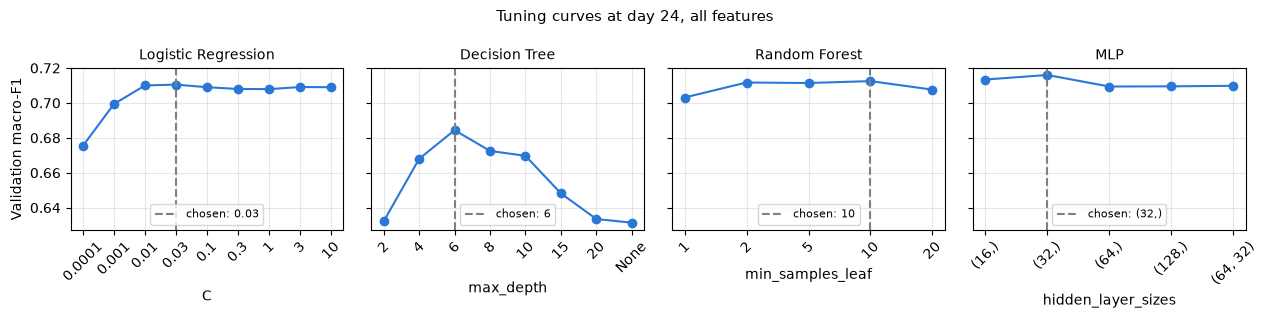

In [8]:
plot_tuning_curves(results); plt.show()

## 5. Results

In [9]:
scores = pd.concat([baseline.table] + [r.table for r in results], ignore_index=True)
models_only = scores[scores["model"] != "Baseline"]
models_only.pivot(index="cutoff", columns=["model", "feature_set"], values="macro_f1")

model       LogisticRegression                   DecisionTree                   RandomForest                          MLP                  
feature_set         background behaviour     all   background behaviour     all   background behaviour     all background behaviour     all
cutoff                                                                                                                                     
0                       0.6117    0.6198  0.6565       0.5935    0.6090  0.6381       0.6148    0.6158  0.6565     0.6091    0.6221  0.6573
24                      0.5977    0.6744  0.7072       0.5762    0.6632  0.6696       0.5992    0.6830  0.7027     0.6019    0.6784  0.7062
60                      0.5955    0.7330  0.7519       0.5759    0.7274  0.7353       0.5993    0.7456  0.7547     0.5950    0.7484  0.7612
120                     0.5714    0.7735  0.7908       0.5618    0.7661  0.7605       0.5655    0.7937  0.7969     0.5832    0.7931  0.7986

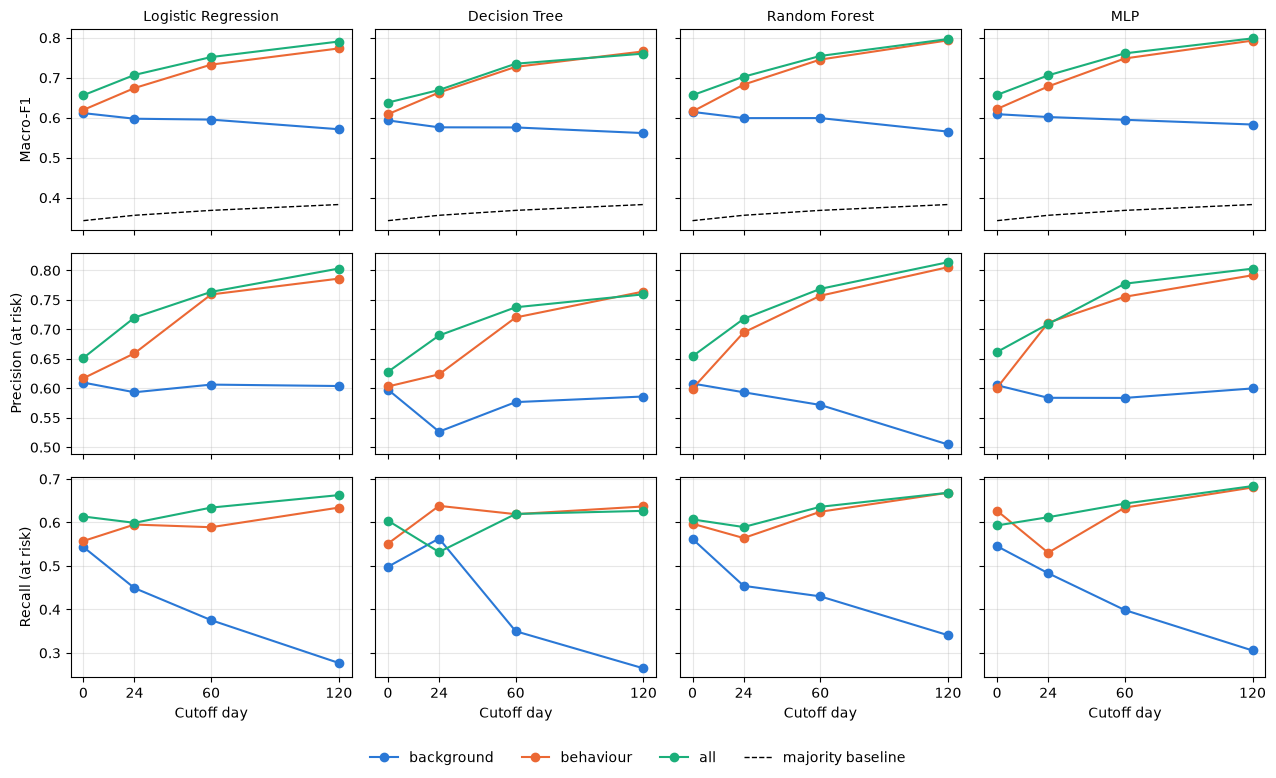

In [10]:
plot_results_grid(scores); plt.show()

**Highest test macro-F1 per model.** Every model peaks at day 120, the latest prediction point.

In [11]:
best_rows = models_only.loc[models_only.groupby("model")["macro_f1"].idxmax()]
best_rows[["model", "cutoff", "feature_set", "best_param", "macro_f1", "precision", "recall"]]

,model,cutoff,feature_set,best_param,macro_f1,precision,recall
26,DecisionTree,120,behaviour,max_depth=6,0.7661,0.7642,0.6368
15,LogisticRegression,120,all,C=10,0.7908,0.8032,0.6629
51,MLP,120,all,"hidden_layer_sizes=(128,)",0.7986,0.8030,0.6837
39,RandomForest,120,all,min_samples_leaf=1,0.7969,0.8139,0.6683


## 6. Error analysis (day 24, all features)

The best classical model is chosen by validation score, then compared with the MLP.

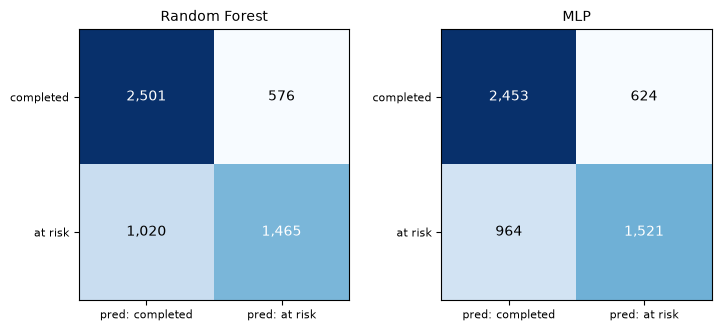

In [12]:
test, cols = splits[24].test, fsets["all"]
best_classical = best_by_validation([r for r in results if r.name != "MLP"])
mlp = next(r for r in results if r.name == "MLP")

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4))
for ax, r in zip(axes, [best_classical, mlp]):
    pred = (r.pipeline.predict_proba(test[cols])[:, 1] >= 0.5).astype(int)
    plot_confusion(confusion_matrix(test[TARGET], pred), MODEL_LABELS[r.name], ax=ax)
fig.tight_layout(); plt.show()

Recall by module for the MLP. Recall is lowest where almost no student has submitted an
assessment by day 24, so the strongest signal does not exist yet. (AAA has too few at-risk
students in the test set to read much into.)

In [13]:
mlp_pred = (mlp.pipeline.predict_proba(test[cols])[:, 1] >= 0.5).astype(int)
recall_by_module(test, mlp_pred)

,at_risk_n,recall,no_submission_%
code_module,,,
AAA,29.0,0.207,11.429
BBB,551.0,0.566,13.297
CCC,359.0,0.730,11.293
DDD,532.0,0.739,35.939
EEE,191.0,0.424,95.984
FFF,635.0,0.616,13.150
GGG,188.0,0.404,98.453


## Takeaways

- **Earlier is harder, but useful.** Every model beats the baseline from day 0, and macro-F1
  rises steadily from about 0.66 (day 0) to about 0.80 (day 120).
- **Behaviour beats background.** Behaviour features drive the improvement; background-only
  models stay flat or decline as early withdrawals leave the risk set.
- **The data, not the model, is the limit.** Logistic regression, random forest and the MLP
  finish within about 0.01 macro-F1 of each other; only the single decision tree lags.
- **Many at-risk students are still missed at day 24** (about 40%), especially in modules
  whose first assessment comes later, which points to module-specific prediction points.